In [25]:
import tensorflow as tf
import pandas as pd
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from skimage.transform import resize
import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import itertools
import os

In [26]:
def block_split(xs, ys, water, patch_size, block_size=448,
                    train_size=0.7, val_size=0.15, n_trials=200, min_patches=10, seed=42):
    rng = np.random.default_rng(seed)
    target = np.array([train_size, val_size, 1 - train_size - val_size])
    # Клетки, которые накрывает каждый патч
    cells = [{(r, c) for r in range(y // block_size, (y + patch_size - 1) // block_size + 1)
                      for c in range(x // block_size, (x + patch_size - 1) // block_size + 1)}
              for x, y in zip(xs, ys)]
    all_cells = sorted(set().union(*cells))
    n_val = round(len(all_cells) * target[1])
    n_test = round(len(all_cells) * target[2])
    best = None
    for _ in range(n_trials):
        # Перемешиваем клетки: первые n_val - val, следующие n_test - test, остальные - train
        order = rng.permutation(len(all_cells))
        cell_set = {all_cells[j]: 1 if i < n_val else 2 if i < n_val + n_test else 0
                    for i, j in enumerate(order)}
        labels = np.full(len(xs), -1)
        for i, patch_cells in enumerate(cells):
            sets = {cell_set[c] for c in patch_cells}
            if len(sets) == 1:
                labels[i] = sets.pop()
        sizes = np.array([(labels == k).sum() for k in range(3)])
        if (sizes < min_patches).any():
            continue
        water_share = np.array([water[labels == k].mean() for k in range(3)])
        score = (np.abs(sizes / sizes.sum() - target).sum()
                  + 0.5 * np.abs(water_share - water_share.mean()).sum() / water_share.mean()
                  + 0.5 * (labels == -1).mean())
        if best is None or score < best[0]:
            best = (score, labels, cell_set)
    if best is None:
        return None
    labels = best[1]
    return tuple(np.where(labels == k)[0] for k in range(3)), best[2]


def load_dataset(data_dir='water_dataset', img_size=(256, 256), train_size=0.7, val_size=0.15,
                  block_size=448):
    """
    Пространственно разделяет данные на три части по клеткам снимка,
    случайно распределенным между выборками:
    - Train (обучение) - около 70%
    - Val (валидация) - около 15%
    - Test (тест) - около 15%
    Патчи, пересекающие границы клеток разных выборок, исключаются, чтобы
    перекрывающиеся патчи не попадали в разные выборки
    """
    print("\n" + "=" * 60)
    print("Загрузка и разделение датасета")
    print("=" * 60)

    image_dir = f'{data_dir}/images'
    mask_dir = f'{data_dir}/masks'
    positions_path = f'{data_dir}/patches.csv'

    if not (os.path.exists(image_dir) and os.path.exists(mask_dir)):
        print("Сначала создайте датасет")
        return None
    if not os.path.exists(positions_path):
        print("Нет файла patches.csv с положением патчей, пересоздайте датасет")
        return None

    common_files = set(os.listdir(image_dir)) & set(os.listdir(mask_dir))
    positions = pd.read_csv(positions_path)
    positions = positions[positions['name'].isin(common_files)].reset_index(drop=True)
    print(f"Найдено {len(positions)} пар изображение-маска")

    images, masks = [], []
    for img_file in positions['name']:
        mask_file = img_file

        # Загрузка и нормализация изображения
        img = plt.imread(f'{image_dir}/{img_file}')
        if img.max() > 1.0:
            if img.max() <= 255:
                img = img.astype(np.float32) / 255.0
            else:
                p2, p98 = np.percentile(img, (2, 98))
                img = np.clip((img - p2) / (p98 - p2 + 1e-8), 0, 1)

        # Ресайз при необходимости
        if img.shape[:2] != img_size:
            img = resize(img, img_size, preserve_range=True, anti_aliasing=True)

        # Загрузка маски
        mask = plt.imread(f'{mask_dir}/{mask_file}')
        if mask.ndim == 3:
            mask = mask[:, :, 0]
        if mask.shape[:2] != img_size:
            mask = resize(mask, img_size, preserve_range=True, anti_aliasing=False)
        mask = (mask > 0.5).astype(np.float32)

        images.append(img.astype(np.float32))
        masks.append(mask)

    X, y = np.array(images), np.array(masks)
    print(f"Размерность данных: X {X.shape}, y {y.shape}")

    # Пространственное разделение на train/val/test по клеткам снимка
    split = block_split(positions['x'].to_numpy(), positions['y'].to_numpy(),
                              y.mean(axis=(1, 2)), int(positions['size'].iloc[0]),
                              block_size, train_size, val_size)
    if split is None:
        print("Не удалось разделить датасет: слишком мало патчей")
        return None
    (train_idx, val_idx, test_idx), cell_set = split

    X_train, y_train = X[train_idx], y[train_idx]
    X_val, y_val = X[val_idx], y[val_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    n_used = len(train_idx) + len(val_idx) + len(test_idx)
    n_cells = [list(cell_set.values()).count(k) for k in range(3)]
    print(f"\nКлетки {block_size}x{block_size}: Train {n_cells[0]}, Val {n_cells[1]}, Test {n_cells[2]}")
    print(f"Исключено патчей на границах клеток разных выборок: {len(X) - n_used}")
    print(f"\nРазделение: Train {X_train.shape[0]}, Val {X_val.shape[0]}, Test {X_test.shape[0]}")
    for name, part in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
        print(f"  {name:5}: {len(part) / n_used * 100:4.1f}% патчей, вода {part.mean() * 100:.1f}% пикселей")

    dataset = {
        'X_train': X_train, 'y_train': y_train,
        'X_val': X_val, 'y_val': y_val,
        'X_test': X_test, 'y_test': y_test
    }
    # Сведения о разбиении для визуализации (plot_dataset_split)
    split_info = {
        'positions': positions, 'block_size': block_size, 'cell_set': cell_set,
        'train_idx': train_idx, 'val_idx': val_idx, 'test_idx': test_idx
    }

    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

In [27]:
def get_augmentation(p=0.5):
    """
    Аугментация позволяет искусственно увеличить размер
    датасета за счет случайных преобразований изображений.
    """
    return A.Compose([
        # Геометрические преобразования
        A.RandomRotate90(p=0.5),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Transpose(p=0.3),
        A.Affine(translate_percent=(-0.1, 0.1), scale=(0.9, 1.1), rotate=(-30, 30), p=0.3),

        # Цветовые преобразования
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
        A.HueSaturationValue(hue_shift_limit=15, sat_shift_limit=25, val_shift_limit=15, p=0.3),

        # Шумы и размытие
        A.GaussNoise(std_range=(0.012, 0.025), p=0.3),
        A.ISONoise(color_shift=(0.01, 0.05), p=0.2),
        A.GaussianBlur(blur_limit=(3, 5), p=0.3),
        A.MedianBlur(blur_limit=5, p=0.2),

        # Погодные эффекты (для спутниковых снимков)
        A.RandomFog(fog_coef_range=(0.1, 0.3), p=0.2),
        A.RandomRain(slant_range=(-10, 10), drop_width=1, p=0.1),
        A.RandomSnow(snow_point_range=(0.1, 0.3), p=0.1),

        # Вырезание (учат модель не полагаться на отдельные пиксели)
        A.CoarseDropout(num_holes_range=(8, 8), hole_height_range=(32, 32),
                        hole_width_range=(32, 32), fill=0, p=0.2)
    ], p=p)


def augment_dataset(X, y, augmentor=None):
    """
    Явная аугментация обучающей выборки: каждый патч пропускается через
    get_augmentation, которая с вероятностью p случайно преобразует его.
    Размер выборки не меняется, часть патчей остается без изменений
    """
    augmentor = augmentor or get_augmentation()
    images, masks = [], []
    for img, mask in zip(X, y):
        augmented = augmentor(image=(img * 255).astype(np.uint8), mask=mask.astype(np.uint8))
        images.append(augmented['image'].astype(np.float32) / 255.0)
        masks.append(augmented['mask'].astype(np.float32))
    return np.stack(images), np.stack(masks)


class UNet:
    def __init__(self, train_dir='model_train'):
        self.train_dir = f'/kaggle/working/{train_dir}'
        os.makedirs(self.train_dir, exist_ok=True)

    def conv_block(self, x, n_filters, kernel_size=3, activation='relu', padding='same', dropout=0.1):
        """
        Сверточный блок для U-Net
        Состоит из двух сверточных слоев с BatchNormalization и
        активацией ReLU.
        """
        x = layers.Conv2D(n_filters, kernel_size, padding=padding)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)

        x = layers.Conv2D(n_filters, kernel_size, padding=padding)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)

        if dropout > 0:
            x = layers.Dropout(dropout)(x)

        return x


    def build_unet(self, input_shape=(256, 256, 3), n_filters=64, n_classes=1):
        """
        Построение архитектуры U-Net
        U-Net состоит из двух частей:
        - Encoder (сжатие): уменьшает размер, увеличивает
        количество каналов
        - Decoder (восстановление): увеличивает размер, используя
        skip-connections
        Skip-connections передают информацию от encoder к decoder,
        что позволяет сохранить детали изображения
        """
        inputs = layers.Input(input_shape)

        # Encoder (сжатие)
        c1 = self.conv_block(inputs, n_filters)
        p1 = layers.MaxPooling2D((2, 2))(c1)

        c2 = self.conv_block(p1, n_filters * 2)
        p2 = layers.MaxPooling2D((2, 2))(c2)

        c3 = self.conv_block(p2, n_filters * 4)
        p3 = layers.MaxPooling2D((2, 2))(c3)

        c4 = self.conv_block(p3, n_filters * 8)
        p4 = layers.MaxPooling2D((2, 2))(c4)

        # Bottleneck (дно)
        c5 = self.conv_block(p4, n_filters * 16)

        # Decoder (восстановление)
        u6 = layers.Conv2DTranspose(n_filters * 8, (2, 2), strides=(2, 2), padding='same')(c5)
        u6 = layers.concatenate([u6, c4])  # Skip-connection
        c6 = self.conv_block(u6, n_filters * 8)

        u7 = layers.Conv2DTranspose(n_filters * 4, (2, 2), strides=(2, 2), padding='same')(c6)
        u7 = layers.concatenate([u7, c3])  # Skip-connection
        c7 = self.conv_block(u7, n_filters * 4)

        u8 = layers.Conv2DTranspose(n_filters * 2, (2, 2), strides=(2, 2), padding='same')(c7)
        u8 = layers.concatenate([u8, c2])  # Skip-connection
        c8 = self.conv_block(u8, n_filters * 2)

        u9 = layers.Conv2DTranspose(n_filters, (2, 2), strides=(2, 2), padding='same')(c8)
        u9 = layers.concatenate([u9, c1])  # Skip-connection
        c9 = self.conv_block(u9, n_filters)

        # Выходной слой с сигмоидой для бинарной классификации
        outputs = layers.Conv2D(n_classes, (1, 1), activation='sigmoid')(c9)

        return Model(inputs, outputs)

    def dice_loss(self, y_true, y_pred, smooth=1e-6):
        """
        DICE LOSS - функция потерь для сегментации
        Dice Loss = 1 - (2*|A∩B| + smooth) / (|A| + |B| + smooth)
        где A - истинная маска, B - предсказанная маска
        Значение от 0 (идеально) до 1 (плохо)
        """
        y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
        y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
        intersection = tf.reduce_sum(y_true_f * y_pred_f)
        score = (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)
        return 1. - score


    def tversky_loss(self, y_true, y_pred, alpha=0.7, beta=0.3, smooth=1e-6):
        """
        TVERSKY LOSS - обобщение Dice Loss с разными весами для ошибок
        Параметры:
        - alpha: вес ложноотрицательных ошибок (FN) - пропущенная вода
        - beta: вес ложноположительных ошибок (FP) - ложная тревога
        Для обнаружения разливов важно alpha > beta (пропуск разлива хуже ложной тревоги)
        """
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        tp = tf.reduce_sum(y_true * y_pred)
        fn = tf.reduce_sum(y_true * (1 - y_pred))
        fp = tf.reduce_sum((1 - y_true) * y_pred)

        tversky = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
        return 1 - tversky


    def combined_loss(self, alpha=0.7, beta=0.3):
        """
        Комбинированная функция потерь
        BCE (Binary Cross-Entropy) дает стабильность,
        Tversky дает точность на границах объектов
        """
        def loss(y_true, y_pred):
            bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
            tv = self.tversky_loss(y_true, y_pred, alpha, beta)
            return bce + tv
        return loss


    def demonstrate_unet(self):
        """
        Демонстрация создания U-Net и функций потерь
        """
        print("\n" + "=" * 60)
        print("Этап 4: Реализация U-Net")
        print("=" * 60)

        unet = self.build_unet(input_shape=(256, 256, 3), n_filters=32)
        print(f"Модель создана! Параметров: {unet.count_params():,}")
        unet.summary()

        # Тестируем функции потерь на простом примере
        y_true = tf.constant([[[[1.0], [0.0]], [[0.0], [1.0]]]])
        y_pred = tf.constant([[[[0.9], [0.1]], [[0.2], [0.8]]]])

        print(f"  Dice Loss: {self.dice_loss(y_true, y_pred).numpy():.4f}")
        print(f"  Tversky Loss (α=0.7, β=0.3): {self.tversky_loss(y_true, y_pred).numpy():.4f}")

        return unet


    def train_model(self, model, X_train, y_train, X_val, y_val, loss_fn, model_name, epochs=5,
                    augment=True, batch_size=8):
        """
        Обучение модели с заданной функцией потерь
        Используются колбэки:
        - ModelCheckpoint: сохраняет лучшую модель
        - EarlyStopping: останавливает обучение при отсутствии прогресса
        - ReduceLROnPlateau: уменьшает learning rate при застое
        При augment=True патчи обучающей выборки случайно аугментируются
        (валидационная выборка не аугментируется)
        """
        print(f"\nОбучение {model_name}...")

        # Нормализация данных
        if X_train.max() > 1.0:
            X_train = X_train.astype('float32') / X_train.max()
            X_val = X_val.astype('float32') / X_val.max()

        if augment:
            X_train, y_train = augment_dataset(X_train, y_train)

        # Метрика IoU для бинарной сегментации
        binary_iou = tf.keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name='iou')

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss=loss_fn,
            metrics=['accuracy', binary_iou]
        )

        callbacks = [
            ModelCheckpoint(
                f'{self.train_dir}/{model_name}.keras',
                save_best_only=True,
                monitor='val_iou', mode='max',
                verbose=1
            ),
            EarlyStopping(
                patience=30, restore_best_weights=True,
                monitor='val_iou', mode='max', verbose=1
            ),
            ReduceLROnPlateau(
                factor=0.5, patience=5, min_lr=1e-6,
                verbose=1
            )
        ]

        history = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            batch_size=batch_size, epochs=epochs,
            shuffle=True, callbacks=callbacks, verbose=1
        )

        return history


    def experiment_tversky_params(self, X_train, y_train, X_val, y_val, param_grid=None, epochs=20, sample_size=100):
        """
        Проверяет разные комбинации alpha и beta:
        - (0.3,0.7): приоритет FP (меньше ложных тревог)
        - (0.5,0.5): равновесный (как Dice)
        - (0.7,0.3): приоритет FN (меньше пропусков) - для экологии
        - (0.8,0.2): сильный приоритет FN
        - (0.9,0.1): экстремальный приоритет FN
        """
        print("\n" + "=" * 60)
        print("Исследование параметров TVERSKY")
        print("=" * 60)

        import pandas as pd

        # Используем подвыборку для ускорения
        if len(X_train) > sample_size:
            idx = np.random.choice(len(X_train), sample_size, replace=False)
            X_train_s, y_train_s = X_train[idx], y_train[idx]
        else:
            X_train_s, y_train_s = X_train, y_train

        if len(X_val) > sample_size // 2:
            idx = np.random.choice(len(X_val), sample_size // 2, replace=False)
            X_val_s, y_val_s = X_val[idx], y_val[idx]
        else:
            X_val_s, y_val_s = X_val, y_val

        param_grid = param_grid or [
            (0.3, 0.7), (0.5, 0.5), (0.7, 0.3), (0.8, 0.2), (0.9, 0.1)
        ]

        results = []
        for alpha, beta in param_grid:
            print(f"\nТестирование α={alpha}, β={beta}...")

            model = self.build_unet(input_shape=(256, 256, 3), n_filters=32)

            def tversky_loss_current(y_true, y_pred):
                return self.tversky_loss(y_true, y_pred, alpha, beta)

            model.compile(optimizer=tf.keras.optimizers.Adam(3e-3), loss=tversky_loss_current)
            model.fit(
                X_train_s, y_train_s,
                validation_data=(X_val_s, y_val_s),
                batch_size=8, epochs=epochs, verbose=0
            )

            y_pred = model.predict(X_val_s, verbose=0)
            y_pred_bin = (y_pred > 0.5).astype(np.float32)

            ious, recalls, precisions = [], [], []
            for i in range(len(X_val_s)):
                true_bin, pred_bin = y_val_s[i] > 0.5, y_pred_bin[i, :, :, 0] > 0.5
                tp = np.sum(true_bin & pred_bin)
                fp = np.sum(~true_bin & pred_bin)
                fn = np.sum(true_bin & ~pred_bin)

                ious.append(tp / (tp + fp + fn + 1e-10))
                recalls.append(tp / (tp + fn + 1e-10))
                precisions.append(tp / (tp + fp + 1e-10))

            results.append({
                'alpha': alpha, 'beta': beta,
                'IoU': np.mean(ious), 'Recall': np.mean(recalls),
                'Precision': np.mean(precisions),
                'F1': 2 * np.mean(precisions) * np.mean(recalls) / (np.mean(precisions) + np.mean(recalls) + 1e-10)
            })

            print(f"  IoU: {results[-1]['IoU']:.4f}, F1: {results[-1]['F1']:.4f}")

        results_df = pd.DataFrame(results)
        self.plot_tversky_experiment(results_df)

        results_df.to_csv(f'{self.train_dir}/tversky_experiment.csv', index=False)
        return results_df


    def plot_tversky_experiment(self, results_df):
        """
        Визуализация результатов эксперимента С TVERSKY LOSS
        Два графика:
        - Сравнение IoU, Recall, Precision для разных параметров
        - F1-score для выбора лучших параметров
        """
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

        x = [f"α={r:.1f}\nβ={b:.1f}" for r, b in zip(results_df['alpha'], results_df['beta'])]
        x_pos = np.arange(len(x))
        width = 0.25

        ax1.bar(x_pos - width, results_df['IoU'], width, label='IoU', alpha=0.8, color='green')
        ax1.bar(x_pos, results_df['Recall'], width, label='Recall', alpha=0.8, color='blue')
        ax1.bar(x_pos + width, results_df['Precision'], width, label='Precision', alpha=0.8, color='red')
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels(x)
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        best_idx = results_df['F1'].argmax()
        ax2.bar(x_pos, results_df['F1'], width, alpha=0.8, color='orange')
        ax2.set_xticks(x_pos)
        ax2.set_xticklabels(x)
        ax2.axhline(y=results_df['F1'].max(), color='red', linestyle='--')
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(f'{self.train_dir}/tversky_experiment.png', dpi=150, bbox_inches='tight')
        plt.show()

In [31]:
(X_train, y_train), (X_val, y_val), (X_test, y_test) = load_dataset(data_dir="/kaggle/input/datasets/shlyapa88man/water-data-nahui/water_dataset")


Загрузка и разделение датасета
Найдено 291 пар изображение-маска
Размерность данных: X (291, 256, 256, 3), y (291, 256, 256)

Клетки 448x448: Train 10, Val 2, Test 2
Исключено патчей на границах клеток разных выборок: 104

Разделение: Train 132, Val 27, Test 28
  Train: 70.6% патчей, вода 19.3% пикселей
  Val  : 14.4% патчей, вода 16.5% пикселей
  Test : 15.0% патчей, вода 17.2% пикселей


In [14]:
unet_web = UNet()
model = unet_web.build_unet(n_filters=16)
history = unet_web.train_model(
    model,
    X_train, y_train,
    X_val, y_val,
    loss_fn=unet_web.dice_loss,
    model_name='unet_dice',
    epochs=50
)
print(history.history)


Обучение unet_dice...
Epoch 1/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6997 - iou: 0.1558 - loss: 0.7647  
Epoch 1: val_iou improved from None to 0.43480, saving model to /kaggle/working/model_train/unet_dice.keras

Epoch 1: finished saving model to /kaggle/working/model_train/unet_dice.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.6846 - iou: 0.1936 - loss: 0.7261 - val_accuracy: 0.8010 - val_iou: 0.4348 - val_loss: 0.7889 - learning_rate: 1.0000e-04
Epoch 2/50
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6946 - iou: 0.2953 - loss: 0.6639
Epoch 2: val_iou did not improve from 0.43480
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - accuracy: 0.6948 - iou: 0.2910 - loss: 0.6692 - val_accuracy: 0.5029 - val_iou: 0.2463 - val_loss: 0.7841 - learning_rate: 1.0000e-04
Epoch 3/50
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.7050 - iou: 0.3390 - loss: 0.5987
Epoch 3: val_iou did not improve from 0.43480
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy

In [15]:
unet_web = UNet()
model = unet_web.build_unet(n_filters=16)
history = unet_web.train_model(
    model,
    X_train, y_train,
    X_val, y_val,
    loss_fn=unet_web.tversky_loss,
    model_name='unet_tversky',
    epochs=50
)
print(history.history)


Обучение unet_tversky...
Epoch 1/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3859 - iou: 0.2166 - loss: 0.6171  
Epoch 1: val_iou improved from None to 0.17929, saving model to /kaggle/working/model_train/unet_tversky.keras

Epoch 1: finished saving model to /kaggle/working/model_train/unet_tversky.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.3845 - iou: 0.2094 - loss: 0.6306 - val_accuracy: 0.2579 - val_iou: 0.1793 - val_loss: 0.7532 - learning_rate: 1.0000e-04
Epoch 2/50
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.4446 - iou: 0.2543 - loss: 0.5801
Epoch 2: val_iou did not improve from 0.17929
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - accuracy: 0.4433 - iou: 0.2391 - loss: 0.5994 - val_accuracy: 0.1826 - val_iou: 0.1672 - val_loss: 0.7481 - learning_rate: 1.0000e-04
Epoch 3/50
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.4924 - iou: 0.2883 - loss: 0.5136
Epoch 3: val_iou did not improve from 0.17929
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step -

In [16]:
unet_web = UNet()
model = unet_web.build_unet(n_filters=16)
history = unet_web.train_model(
    model,
    X_train, y_train,
    X_val, y_val,
    loss_fn=unet_web.combined_loss(),
    model_name='unet_combined',
    epochs=50
)
print(history.history)


Обучение unet_combined...
Epoch 1/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6859 - iou: 0.1736 - loss: 1.3015  
Epoch 1: val_iou improved from None to 0.00002, saving model to /kaggle/working/model_train/unet_combined.keras

Epoch 1: finished saving model to /kaggle/working/model_train/unet_combined.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.6872 - iou: 0.2092 - loss: 1.2814 - val_accuracy: 0.8352 - val_iou: 2.0572e-05 - val_loss: 1.4293 - learning_rate: 1.0000e-04
Epoch 2/50
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6852 - iou: 0.2822 - loss: 1.1914
Epoch 2: val_iou did not improve from 0.00002
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.7053 - iou: 0.2858 - loss: 1.1831 - val_accuracy: 0.8352 - val_iou: 0.0000e+00 - val_loss: 1.4119 - learning_rate: 1.0000e-04
Epoch 3/50
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.7048 - iou: 0.2628 - loss: 1.2068
Epoch 3: val_iou improved from 0.00002 to 0.00040, saving model to /kaggle/w


Исследование параметров TVERSKY

Тестирование α=0.3, β=0.7...
  IoU: 0.2230, F1: 0.3218

Тестирование α=0.5, β=0.5...
  IoU: 0.2728, F1: 0.3754

Тестирование α=0.7, β=0.3...
  IoU: 0.1731, F1: 0.2974

Тестирование α=0.8, β=0.2...
  IoU: 0.2814, F1: 0.4383

Тестирование α=0.9, β=0.1...
  IoU: 0.2546, F1: 0.4123


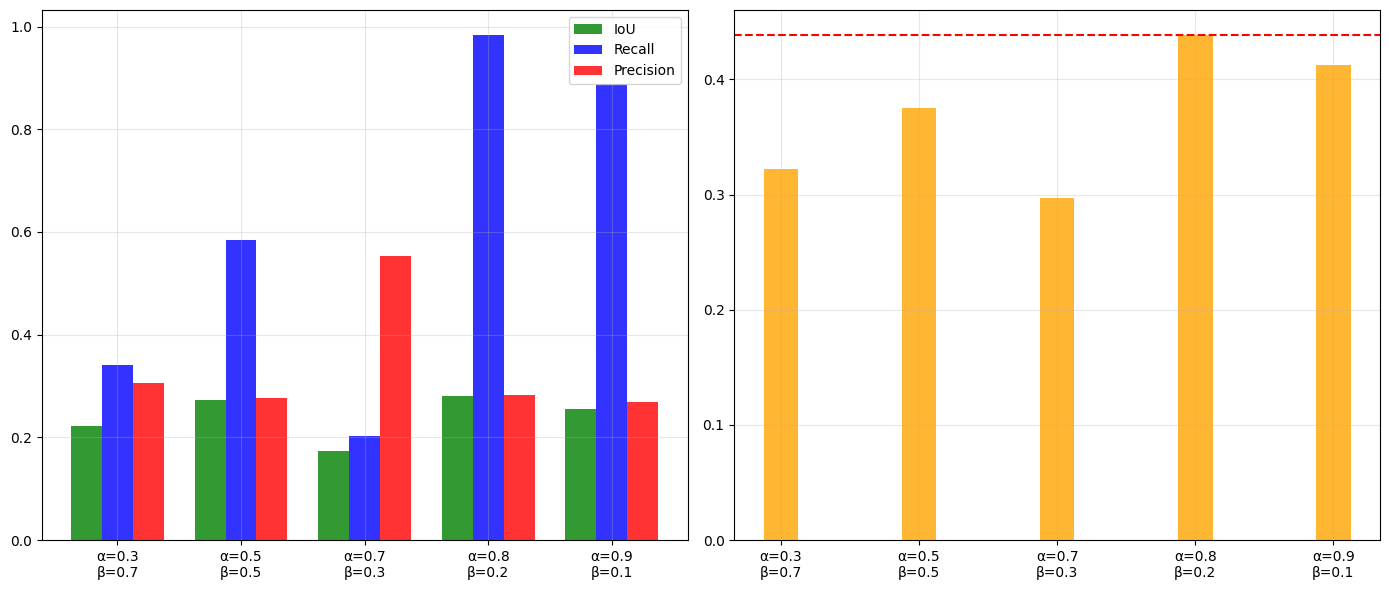

,alpha,beta,IoU,Recall,Precision,F1
0,0.3,0.7,0.222989,0.340333,0.305239,0.321832
1,0.5,0.5,0.272779,0.583794,0.276621,0.375376
2,0.7,0.3,0.173059,0.203444,0.552384,0.297367
3,0.8,0.2,0.281394,0.983007,0.282028,0.438305
4,0.9,0.1,0.254627,0.887390,0.268565,0.412338


In [33]:
unet_web = UNet()
tversky_results = unet_web.experiment_tversky_params(
    X_train, y_train,
    X_val, y_val,
    epochs=20
)
tversky_results

In [32]:
from skimage.morphology import remove_small_objects, closing, disk
from skimage.filters import threshold_otsu

TRAIN_DIR = '/kaggle/input/datasets/shlyapa88man/water-data-nahui/model_train'


def postprocess_mask(mask, min_size=50):
    """
    Постобработка бинарной маски
    Удаляет маленькие объекты и заполняет дыры
    """
    mask_bool = mask > 0.5
    mask_clean = remove_small_objects(mask_bool, min_size=min_size)
    return closing(mask_clean, disk(2)).astype(np.float32)


def calculate_metrics(true_mask, pred_mask):
    """
    Расчет метрик качества сегментации
    IoU (Intersection over Union) - основная метрика
    """
    true_bin, pred_bin = true_mask > 0.5, pred_mask > 0.3
    tp = np.sum(true_bin & pred_bin)
    fp = np.sum(~true_bin & pred_bin)
    fn = np.sum(true_bin & ~pred_bin)
    return {'IoU': tp / (tp + fp + fn + 1e-10), 'TP': tp, 'FP': fp, 'FN': fn}


def find_optimal_threshold(model, X_val, y_val, model_name="", thresholds=np.arange(0.3, 0.9, 0.05)):
    """
    Поиск оптимального порога бинаризации для модели
    Перебирает пороги от 0.3 до 0.85 и выбирает тот,
    при котором IoU на валидационной выборке максимален.
    """
    print(f"\nПоиск оптимального порога для {model_name}...")

    best_threshold, best_iou = 0.5, 0
    threshold_results = []

    n_samples = min(30, len(X_val))
    X_sample, y_sample = X_val[:n_samples], y_val[:n_samples]
    # Предсказание считаем один раз, дальше меняется только порог
    preds = model.predict(X_sample, batch_size=4, verbose=0)[..., 0]

    for threshold in thresholds:
        ious = []
        for i in range(n_samples):
            pred_bin = postprocess_mask((preds[i] > threshold).astype(np.float32))
            iou = calculate_metrics(y_sample[i], pred_bin)['IoU']
            ious.append(iou)

        mean_iou = np.mean(ious)
        threshold_results.append((threshold, mean_iou))

        if mean_iou > best_iou:
            best_iou, best_threshold = mean_iou, threshold
            print(f"Порог {threshold:.2f}: IoU = {mean_iou:.4f} (НОВЫЙ ЛУЧШИЙ)")
        else:
            print(f"Порог {threshold:.2f}: IoU = {mean_iou:.4f}")

    plot_threshold_analysis(threshold_results, model_name)

    return best_threshold, best_iou


def plot_threshold_analysis(threshold_results, model_name):
    """
    ВИЗУАЛИЗАЦИЯ ЗАВИСИМОСТИ IoU ОТ ПОРОГА
    Показывает, как меняется качество сегментации при изменении
    порога, и отмечает оптимальное значение.
    """
    thresholds, ious = zip(*threshold_results)

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, ious, 'b-o', linewidth=2, markersize=8)
    plt.xlabel('Порог бинаризации')
    plt.ylabel('IoU')
    plt.title(f'Зависимость качества от порога\n{model_name}')
    plt.grid(True, alpha=0.3)

    best_idx = np.argmax(ious)
    best_threshold, best_iou = thresholds[best_idx], ious[best_idx]

    plt.axvline(x=best_threshold, color='red', linestyle='--', alpha=0.7)
    plt.scatter([best_threshold], [best_iou], color='red', s=200, zorder=5)
    # Подпись смещена от точки оптимума в пунктах, а не в единицах IoU,
    # чтобы не выходить за график при малом разбросе IoU
    plt.annotate(
        f'Оптимум: {best_threshold:.2f}\nIoU={best_iou:.4f}',
        xy=(best_threshold, best_iou), xytext=(10, -35), textcoords='offset points',
        fontsize=10, color='red'
    )

    plt.tight_layout()
    plt.savefig(
        f'/kaggle/working/model_train/threshold_analysis_{model_name.replace(" ", "_")}.png',
        dpi=150, bbox_inches='tight'
    )
    plt.show()


def visualize_predictions(models_dict, X_test, y_test, n_samples=4, save=True):
    """
    Визуализация предсказаний моделей с адаптивными порогами
    Показывает для каждого тестового примера:
    - оригинал
    - идеальную маску
    - предсказания всех моделей
    - карту ошибок лучшей модели
    """
    print("\n" + "=" * 60)
    print("Визуализация предсказаний")
    print("=" * 60)

    indices = np.random.choice(len(X_test), min(n_samples, len(X_test)), replace=False)
    n_models = len(models_dict)

    fig, axes = plt.subplots(len(indices), n_models + 3, figsize=(4 * (n_models + 3), 4 * len(indices)))
    if len(indices) == 1:
        axes = axes.reshape(1, -1)

    # Эмпирически подобранные пороги для каждой модели
    optimal_thresholds = {'Dice Loss': 0.65, 'Tversky Loss': 0.5, 'Combined Loss': 0.45}

    for row, idx in enumerate(indices):
        img, true_mask = X_test[idx], y_test[idx].squeeze()
        col = 0

        axes[row, col].imshow(img)
        axes[row, col].set_title('Снимок')
        axes[row, col].axis('off')
        col += 1

        axes[row, col].imshow(true_mask, cmap='Blues', vmin=0, vmax=1)
        axes[row, col].set_title('Идеальная маска')
        axes[row, col].axis('off')
        col += 1

        ious = []
        for name, model in models_dict.items():
            pred_raw = model.predict(img[np.newaxis], verbose=0)[0, :, :, 0]
            threshold = optimal_thresholds.get(name, 0.5)

            # Для Dice Loss используем Otsu если предсказания слишком высокие
            if name == 'Dice Loss' and pred_raw.mean() > 0.7:
                try:
                    pred_norm = ((pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-8) * 255).astype(np.uint8)
                    threshold = threshold_otsu(pred_norm) / 255.0
                except:
                    threshold = 0.7

            pred_bin = postprocess_mask((pred_raw > threshold).astype(np.float32))
            iou = calculate_metrics(true_mask, pred_bin)['IoU']
            ious.append((name, iou))

            axes[row, col].imshow(pred_bin, cmap='Blues', vmin=0, vmax=1)
            axes[row, col].set_title(f'{name}\nпорог={threshold:.2f}\nIoU={iou:.3f}', fontsize=9)
            axes[row, col].axis('off')
            col += 1

        # Карта ошибок лучшей модели
        if ious:
            best_name, best_iou = max(ious, key=lambda x: x[1])
            best_model = models_dict[best_name]
            pred_raw = best_model.predict(img[np.newaxis], verbose=0)[0, :, :, 0]
            threshold = optimal_thresholds.get(best_name, 0.5)
            pred_bin = postprocess_mask((pred_raw > threshold).astype(np.float32))

            error_map = np.zeros((*pred_bin.shape, 3))
            tp_mask = (true_mask > 0.5) & (pred_bin > 0.5)  # True Positive (зеленый)
            fp_mask = (true_mask <= 0.5) & (pred_bin > 0.5)  # False Positive (красный)
            fn_mask = (true_mask > 0.5) & (pred_bin <= 0.5)  # False Negative (желтый)
            error_map[tp_mask] = [0, 1, 0]
            error_map[fp_mask] = [1, 0, 0]
            error_map[fn_mask] = [1, 1, 0]

            axes[row, -1].imshow(error_map)
            axes[row, -1].set_title(f'Ошибки\n{best_name}: {best_iou:.3f}', fontsize=10)
            axes[row, -1].axis('off')

    plt.tight_layout()
    if save:
        plt.savefig(f'/kaggle/working/model_train/test_predictions.png', dpi=150, bbox_inches='tight')
    plt.show()


def visualize_predictions_with_thresholds(models_dict, X_test, y_test, optimal_thresholds=None, n_samples=4, save=True):
    """
    Визуализация предсказаний с оптимальными порогами
    Использует найденные ранее оптимальные пороги для каждой модели.
    """
    print("\n" + "=" * 60)
    print("Визуализация - оптимальные пороги")
    print("=" * 60)

    if optimal_thresholds is None:
        optimal_thresholds = {name: 0.5 for name in models_dict.keys()}

    indices = np.random.choice(len(X_test), min(n_samples, len(X_test)), replace=False)
    n_models = len(models_dict)

    fig, axes = plt.subplots(len(indices), n_models + 3, figsize=(4 * (n_models + 3), 4 * len(indices)))
    if len(indices) == 1:
        axes = axes.reshape(1, -1)

    for row, idx in enumerate(indices):
        img, true_mask = X_test[idx], y_test[idx].squeeze()
        col = 0

        axes[row, col].imshow(img)
        axes[row, col].set_title('Снимок')
        axes[row, col].axis('off')
        col += 1

        axes[row, col].imshow(true_mask, cmap='Blues', vmin=0, vmax=1)
        axes[row, col].set_title('Идеальная маска')
        axes[row, col].axis('off')
        col += 1

        ious = []
        for name, model in models_dict.items():
            pred_raw = model.predict(img[np.newaxis], verbose=0)[0, :, :, 0]
            threshold = optimal_thresholds.get(name, 0.5)
            pred_bin = postprocess_mask((pred_raw > threshold).astype(np.float32))
            iou = calculate_metrics(true_mask, pred_bin)['IoU']
            ious.append((name, iou))

            axes[row, col].imshow(pred_bin, cmap='Blues', vmin=0, vmax=1)
            axes[row, col].set_title(f'{name}\nпорог={threshold:.2f}\nIoU={iou:.3f}', fontsize=9)
            axes[row, col].axis('off')
            col += 1

        # Карта ошибок лучшей модели
        if ious:
            best_name, best_iou = max(ious, key=lambda x: x[1])
            best_model = models_dict[best_name]
            pred_raw = best_model.predict(img[np.newaxis], verbose=0)[0, :, :, 0]
            threshold = optimal_thresholds.get(best_name, 0.5)
            pred_bin = postprocess_mask((pred_raw > threshold).astype(np.float32))

            error_map = np.zeros((*pred_bin.shape, 3))
            tp_mask = (true_mask > 0.5) & (pred_bin > 0.5)
            fp_mask = (true_mask <= 0.5) & (pred_bin > 0.5)
            fn_mask = (true_mask > 0.5) & (pred_bin <= 0.5)
            error_map[tp_mask] = [0, 1, 0]
            error_map[fp_mask] = [1, 0, 0]
            error_map[fn_mask] = [1, 1, 0]

            axes[row, -1].imshow(error_map)
            axes[row, -1].set_title(f'Ошибки\n{best_name}: {best_iou:.3f}', fontsize=10)
            axes[row, -1].axis('off')

    plt.tight_layout()
    if save:
        plt.savefig(f'/kaggle/working/model_train/test_predictions_optimal.png', dpi=150, bbox_inches='tight')
    plt.show()


Поиск оптимального порога для Dice Loss...
Порог 0.30: IoU = 0.5514 (НОВЫЙ ЛУЧШИЙ)
Порог 0.35: IoU = 0.5542 (НОВЫЙ ЛУЧШИЙ)
Порог 0.40: IoU = 0.5539
Порог 0.45: IoU = 0.5537
Порог 0.50: IoU = 0.5522
Порог 0.55: IoU = 0.5502
Порог 0.60: IoU = 0.5482
Порог 0.65: IoU = 0.5437
Порог 0.70: IoU = 0.5408
Порог 0.75: IoU = 0.5361
Порог 0.80: IoU = 0.5306


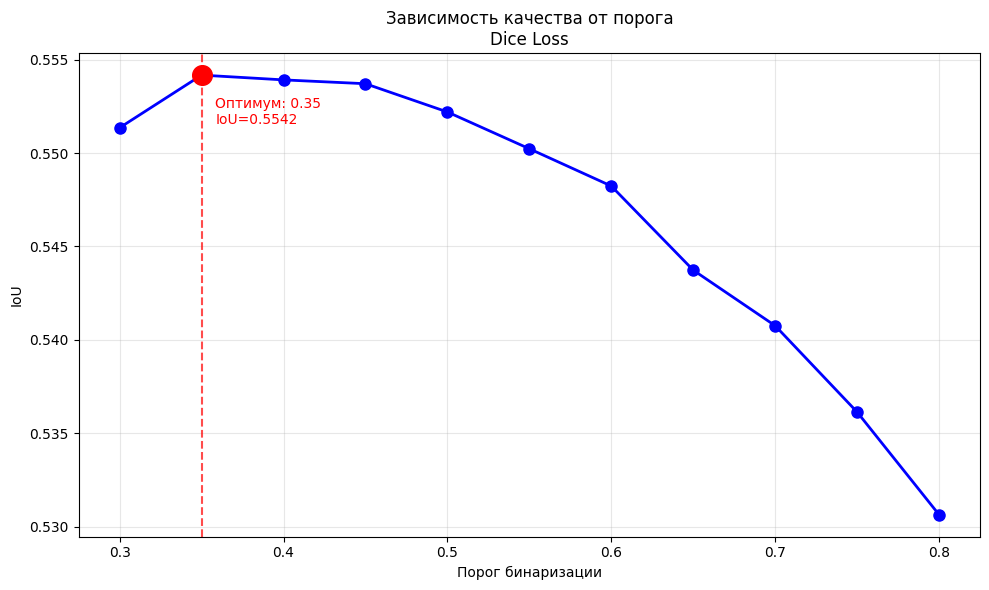


Поиск оптимального порога для Tversky Loss...
Порог 0.30: IoU = 0.4669 (НОВЫЙ ЛУЧШИЙ)
Порог 0.35: IoU = 0.5086 (НОВЫЙ ЛУЧШИЙ)
Порог 0.40: IoU = 0.5383 (НОВЫЙ ЛУЧШИЙ)
Порог 0.45: IoU = 0.5417 (НОВЫЙ ЛУЧШИЙ)
Порог 0.50: IoU = 0.5379
Порог 0.55: IoU = 0.5292
Порог 0.60: IoU = 0.5247
Порог 0.65: IoU = 0.5245
Порог 0.70: IoU = 0.5208
Порог 0.75: IoU = 0.5169
Порог 0.80: IoU = 0.5083


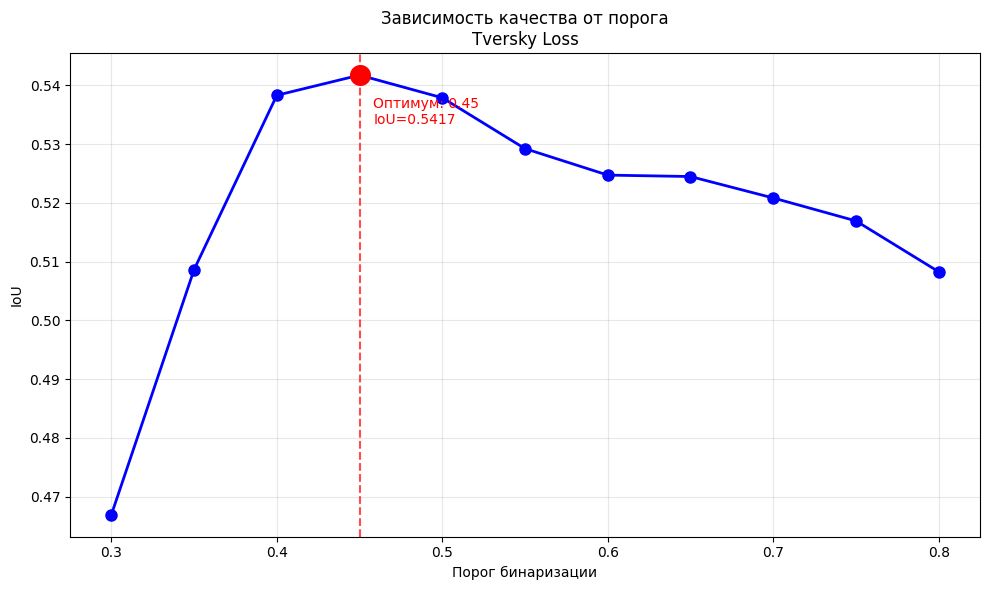


Поиск оптимального порога для Combined Loss...
Порог 0.30: IoU = 0.1648 (НОВЫЙ ЛУЧШИЙ)
Порог 0.35: IoU = 0.1648
Порог 0.40: IoU = 0.2397 (НОВЫЙ ЛУЧШИЙ)
Порог 0.45: IoU = 0.3731 (НОВЫЙ ЛУЧШИЙ)
Порог 0.50: IoU = 0.4137 (НОВЫЙ ЛУЧШИЙ)
Порог 0.55: IoU = 0.3774
Порог 0.60: IoU = 0.3554
Порог 0.65: IoU = 0.3549
Порог 0.70: IoU = 0.3470
Порог 0.75: IoU = 0.3248
Порог 0.80: IoU = 0.2810


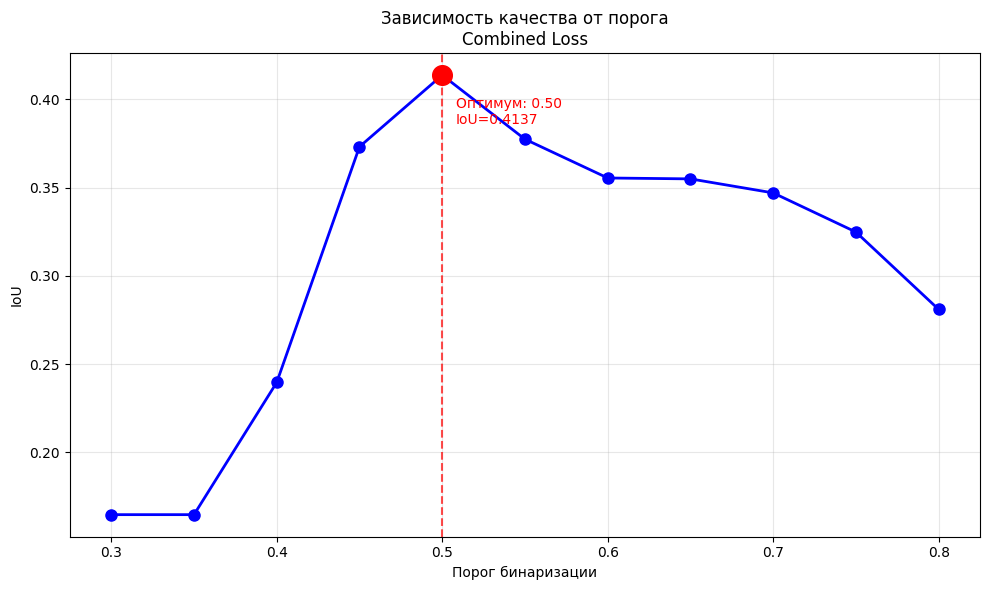


Визуализация предсказаний


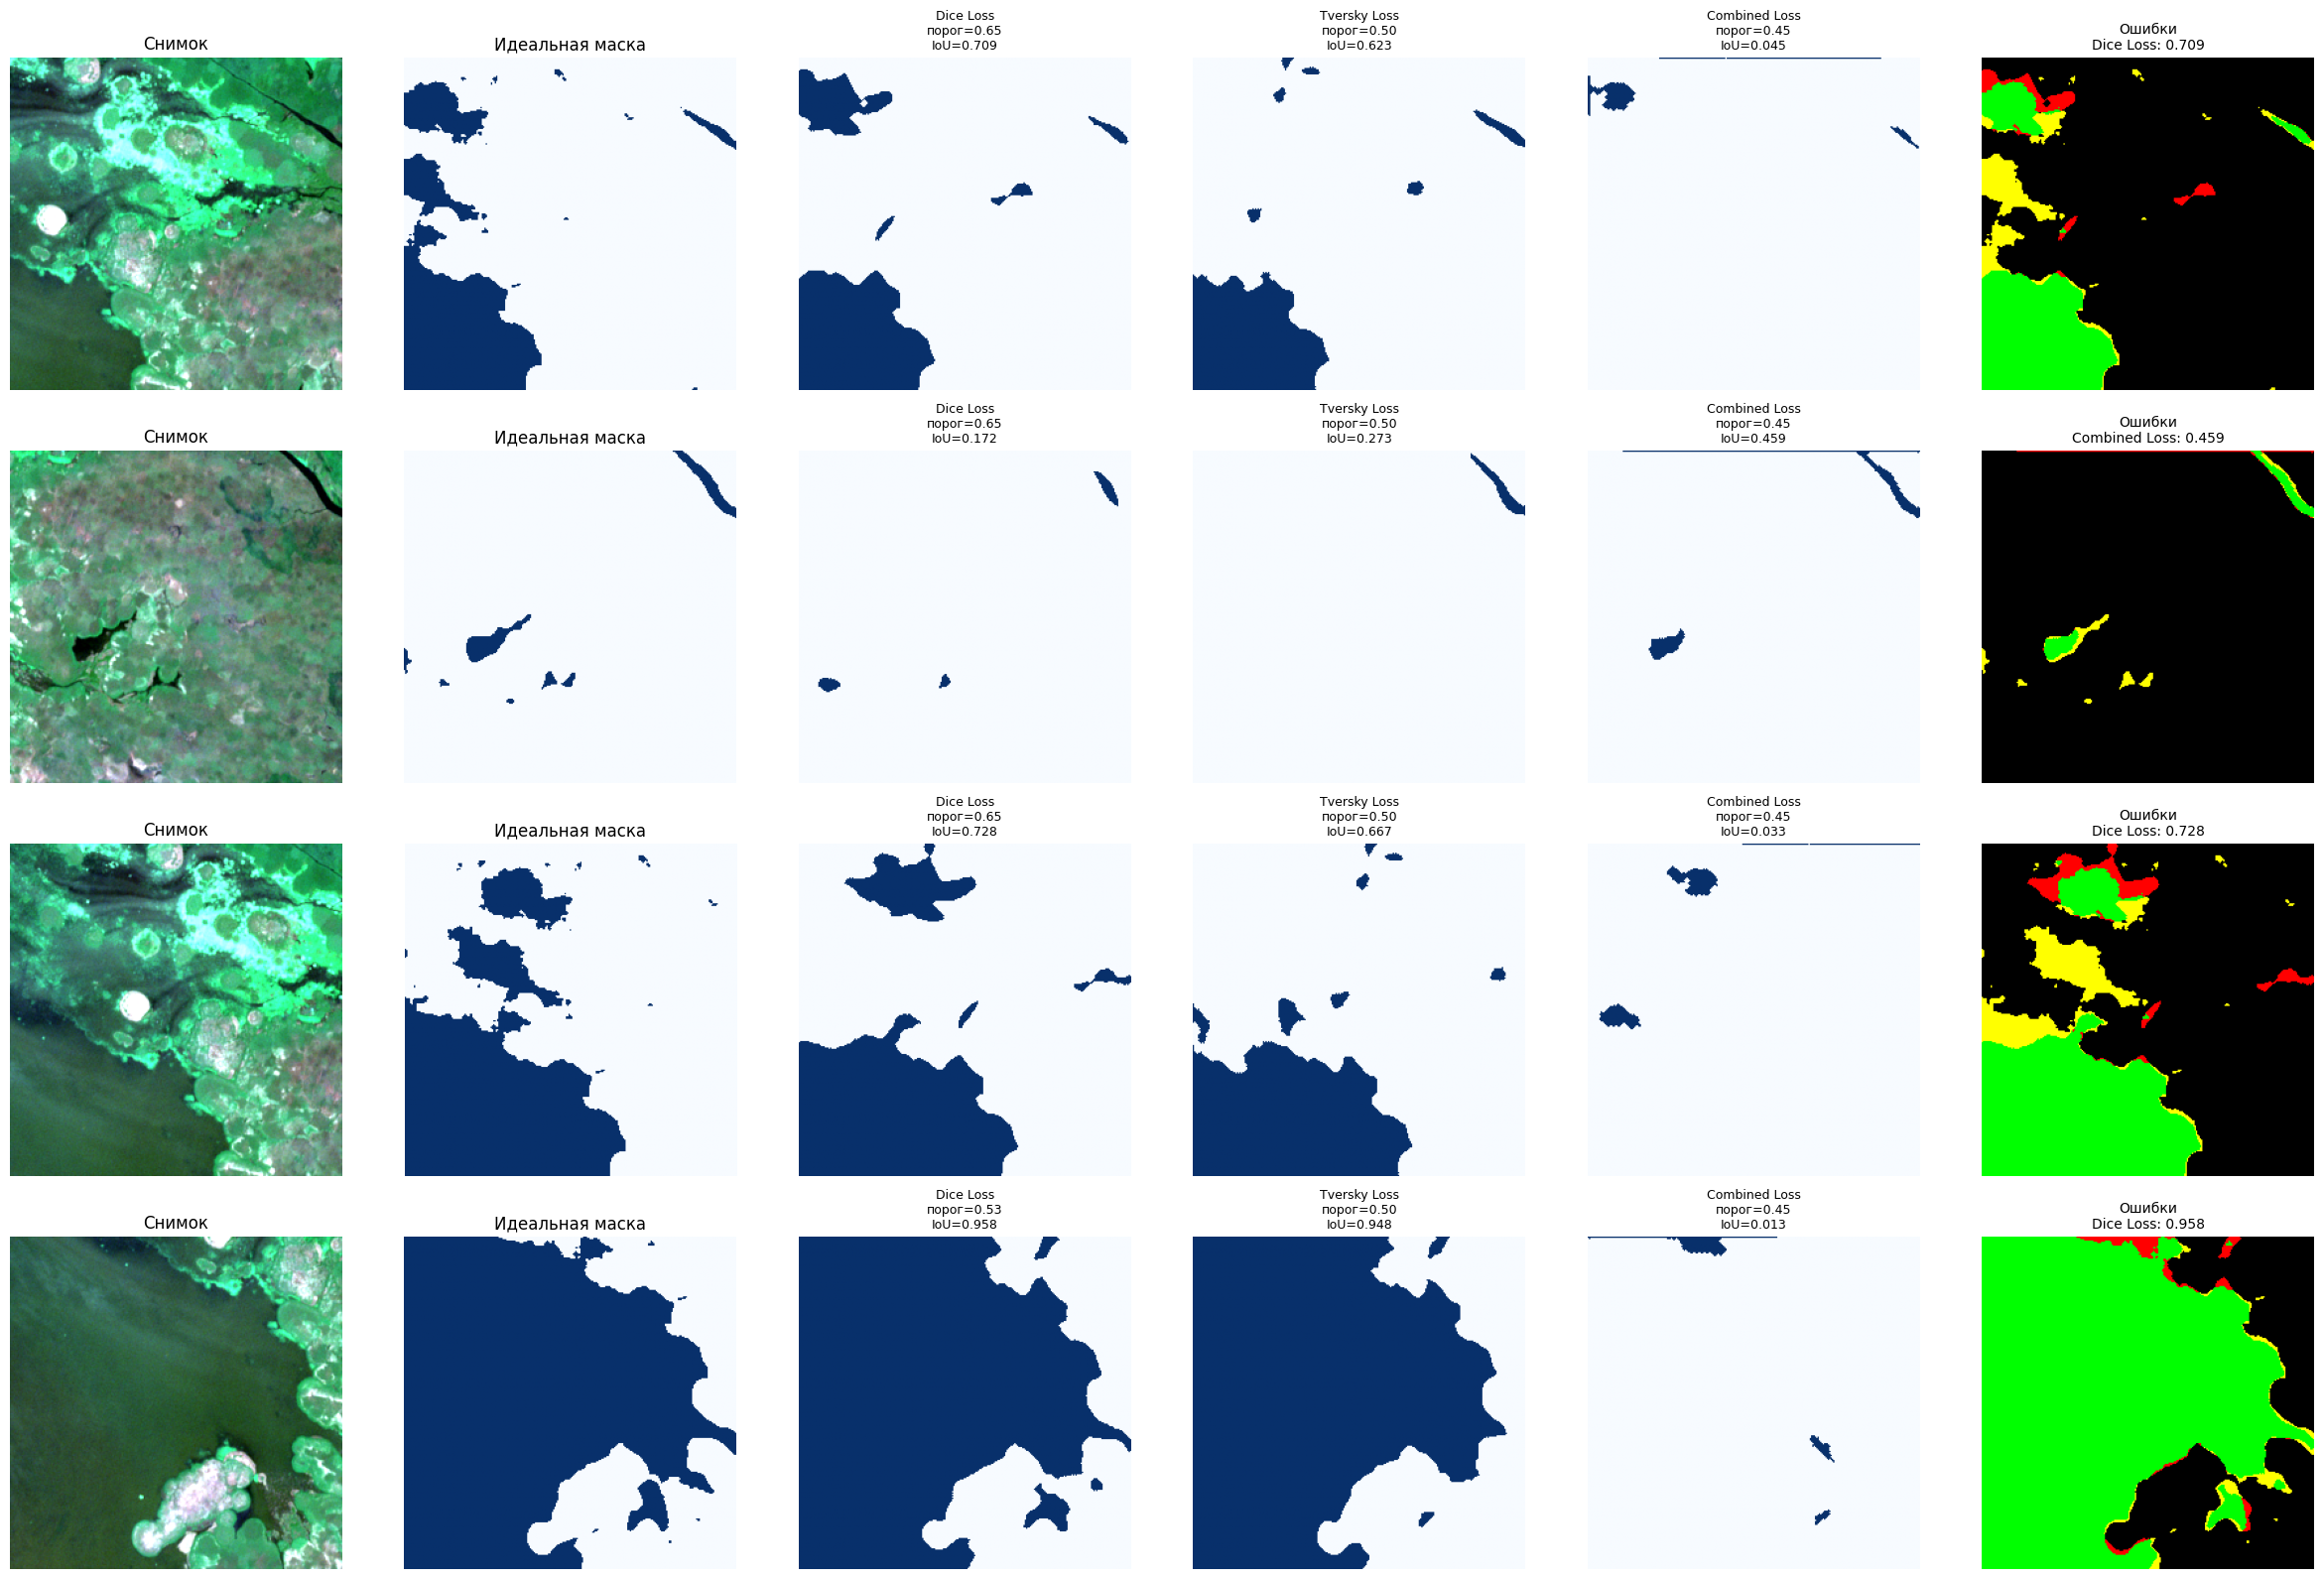


Визуализация - оптимальные пороги


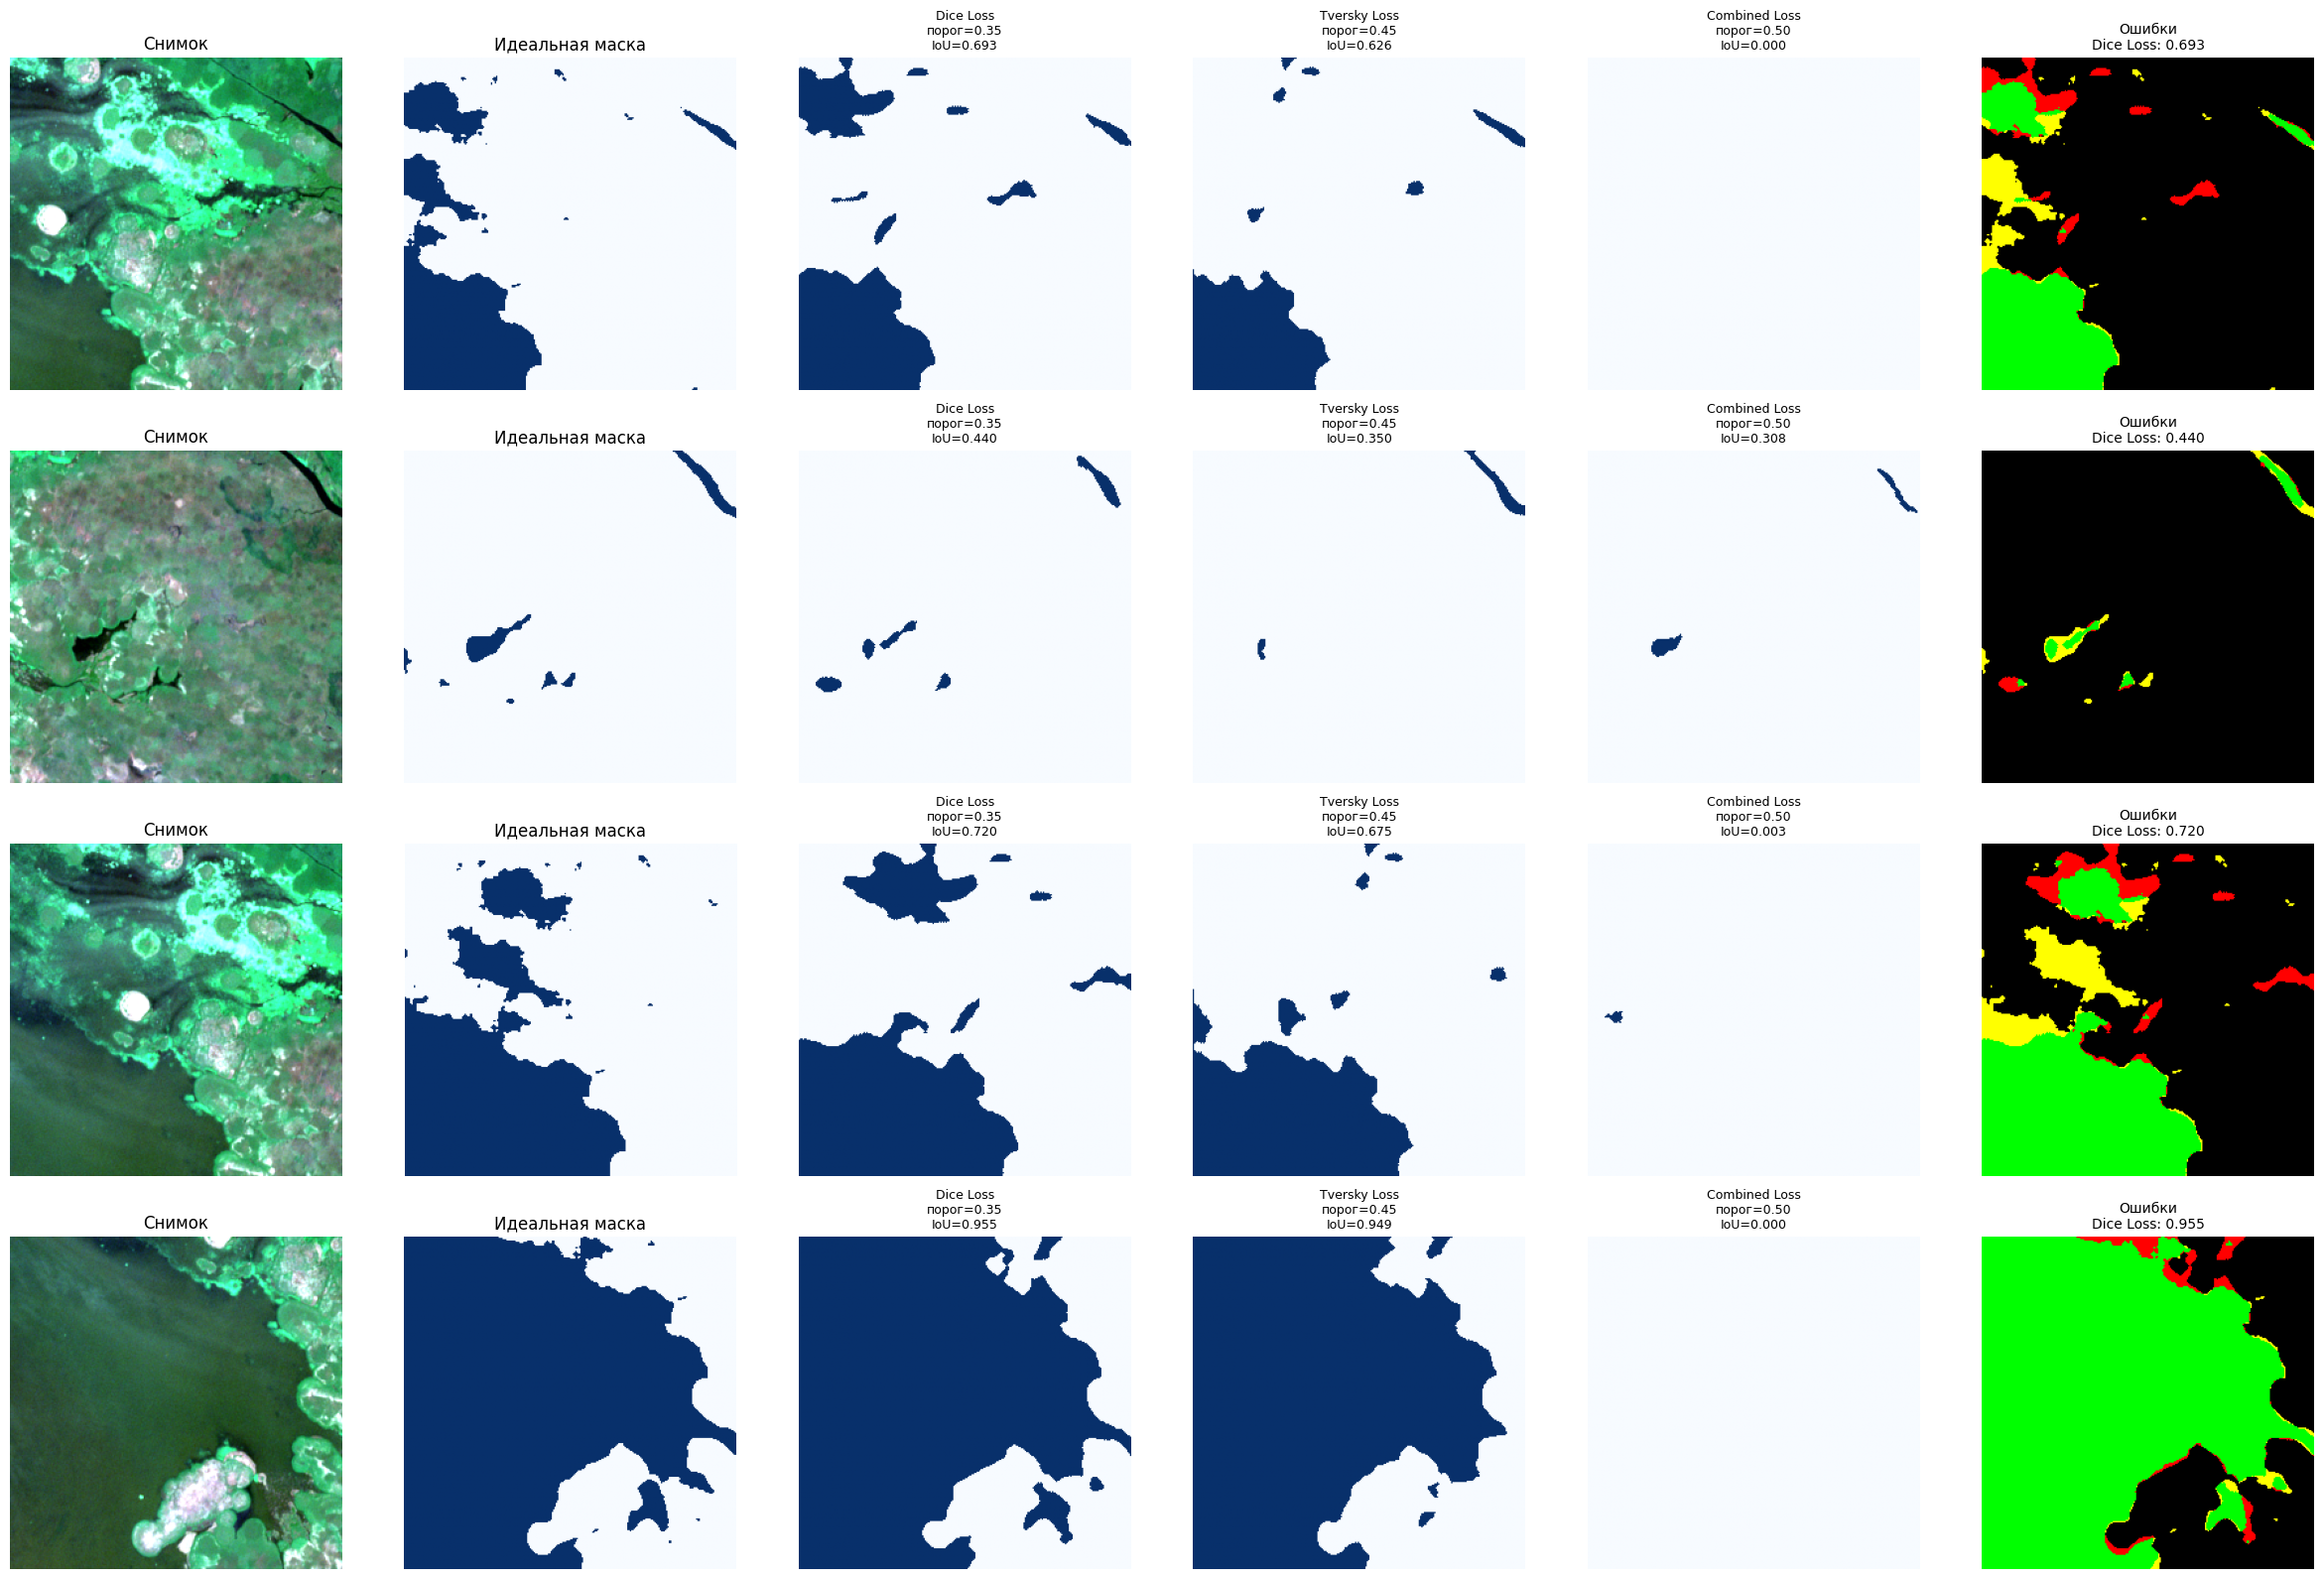

In [24]:
# Задача 5.3: модели из Drive, пороги подбираются на val, визуализация на test
models = {
    'Dice Loss': tf.keras.models.load_model(f'{TRAIN_DIR}/unet_dice.keras', compile=False),
    'Tversky Loss': tf.keras.models.load_model(f'{TRAIN_DIR}/unet_tversky.keras', compile=False),
    'Combined Loss': tf.keras.models.load_model(f'{TRAIN_DIR}/unet_combined.keras', compile=False),
}
thresholds = {}
for name, model in models.items():
    thresholds[name], _ = find_optimal_threshold(model, X_val, y_val, model_name=name,
                                                 thresholds=np.arange(0.3, 0.85, 0.05))

# Одинаковый seed, чтобы "до" и "после" показывали одни и те же патчи
np.random.seed(42)
visualize_predictions(models, X_test, y_test, n_samples=4)
np.random.seed(42)
visualize_predictions_with_thresholds(models, X_test, y_test, thresholds, n_samples=4)